<a href="https://colab.research.google.com/github/mykolalypko/cloud-lab-lypko/blob/main/notebooks/lab_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 11. Gemini Notebook, Google Colab і GitHub
**Виконав:** Липко Микола | **Група:** Пі-25-01 | **Варіант:** 17 — Облік часу команди

In [3]:
import sys, platform
student = "Липко Микола"
group = "Пі-25-01"
print("Лабораторна робота: Gemini, Colab, GitHub")
print("Виконав(ла):", student, "| група:", group)
print("Python:", sys.version.split()[0])
print("Платформа:", platform.system())

Лабораторна робота: Gemini, Colab, GitHub
Виконав(ла): Липко Микола | група: Пі-25-01
Python: 3.13.18
Платформа: Linux


## 1. Набір даних
**Дані навчальні, синтетичні** (вигадані, імена учасників знеособлені). Поля: `member` (учасник), `activity` (вид діяльності), `hours` (години), `week` (тиждень), `project` (проєкт).

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

url = ("https://raw.githubusercontent.com/mykolalypko/"
       "cloud-lab-lypko/main/data/time_log.csv")
try:
    df = pd.read_csv(url)           # читання за raw URL з GitHub
except Exception:
    df = pd.read_csv("time_log.csv")  # запасний варіант: файл, завантажений у панель файлів Colab

print(df.shape)
df.info()
df.head()

(40, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   member    40 non-null     object 
 1   activity  40 non-null     object 
 2   hours     40 non-null     float64
 3   week      40 non-null     int64  
 4   project   40 non-null     object 
dtypes: float64(1), int64(1), object(3)
memory usage: 1.7+ KB


,member,activity,hours,week,project
0,Member_A,Development,6.5,1,MobileApp
1,Member_A,Code review,2.0,1,MobileApp
2,Member_B,Development,5.0,1,WebApp
3,Member_B,Meetings,2.5,1,MobileApp
4,Member_C,Development,8.0,1,MobileApp


### Перевірка даних
Перевіряємо дублікати, пропуски та діапазон годин (очікуємо 0.5–8 год на запис).

In [5]:
print("Дублікати:", df.duplicated().sum())
print("Пропуски:\n", df.isna().sum())
print("Діапазон hours:", df["hours"].min(), "-", df["hours"].max())
df.to_csv("time_log.csv", index=False)

Дублікати: 0
Пропуски:
 member      0
activity    0
hours       0
week        0
project     0
dtype: int64
Діапазон hours: 0.5 - 8.0


## 2. Описова статистика

In [6]:
df["hours"].describe()

,hours
count,40.000000
mean,2.762500
std,2.270173
min,0.500000
25%,1.000000
50%,2.000000
75%,3.250000
max,8.000000


## 3. Розподіл годин за видами діяльності (питання варіанта)
Групуємо за `activity`, рахуємо суму годин і частку від загального часу.

In [7]:
by_act = df.groupby("activity")["hours"].sum().sort_values(ascending=False)
share = (by_act / by_act.sum() * 100).round(1)
result = pd.DataFrame({"hours": by_act, "share_%": share})
result

,hours,share_%
activity,,
Development,69.5,62.9
Meetings,9.5,8.6
Testing,9.5,8.6
Documentation,9.0,8.1
Code review,7.5,6.8
Planning,5.5,5.0


### Відбір за умовою
Довгі наради: записи діяльності *Meetings* тривалістю ≥ 2 год, а також загальні години кожного учасника.

In [8]:
long_meetings = df[(df["activity"] == "Meetings") & (df["hours"] >= 2)]
print("Довгі наради (>= 2 год):")
print(long_meetings)
print()
print("Години за учасниками:")
print(df.groupby("member")["hours"].sum())

Довгі наради (>= 2 год):
      member  activity  hours  week    project
3   Member_B  Meetings    2.5     1  MobileApp
5   Member_C  Meetings    2.0     1     WebApp
25  Member_C  Meetings    2.5     3  MobileApp

Години за учасниками:
member
Member_A    29.5
Member_B    30.0
Member_C    26.5
Member_D    12.0
Member_E    12.5
Name: hours, dtype: float64


## 4. Діаграма

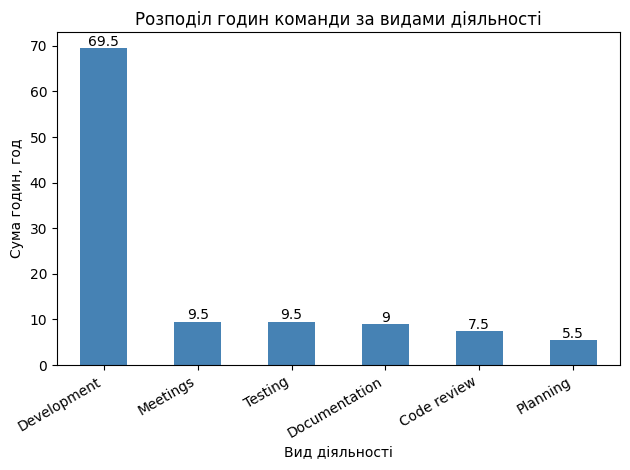

In [14]:
ax = by_act.plot(kind="bar", color="steelblue")
plt.title("Розподіл годин команди за видами діяльності")
plt.xlabel("Вид діяльності")
plt.ylabel("Сума годин, год")
plt.xticks(rotation=30, ha="right")
for i, v in enumerate(by_act):
    ax.text(i, v + 0.5, f"{v:g}", ha="center")
plt.tight_layout()
plt.savefig("chart.png", dpi=150)
plt.show()

## 5. Журнал AI
| № | Запит | Відповідь AI | Що зробив(ла) я |
|---|-------|--------------|-----------------|
| 1 | *(впишіть свій запит до Gemini: додаткова діаграма, напр. частка годин за видами діяльності)* | *(коротко: що запропонував AI)* | *(що змінили, як перевірили, що суми збігаються з df)* |
| 2 | *(скопіюйте помилку, напр. KeyError: 'activty', після навмисного друку df["activty"])* | *(пояснення AI)* | *(звірили з df.columns, виправили на activity)* |

> Заповніть таблицю після реальної роботи з Gemini — журнал має відображати саме ваші запити.

## 6. Висновки
Найбільше часу команда витрачає на розробку (Development) — приблизно 63 % усіх годин. Решта видів діяльності (наради, тестування, документація, код-рев'ю, планування) займають по 5–9 % кожен. Розподіл є зсунутим у бік розробки, тому за потреби варто збільшити частку тестування й код-рев'ю. Дані синтетичні, тож висновки мають навчальний характер.

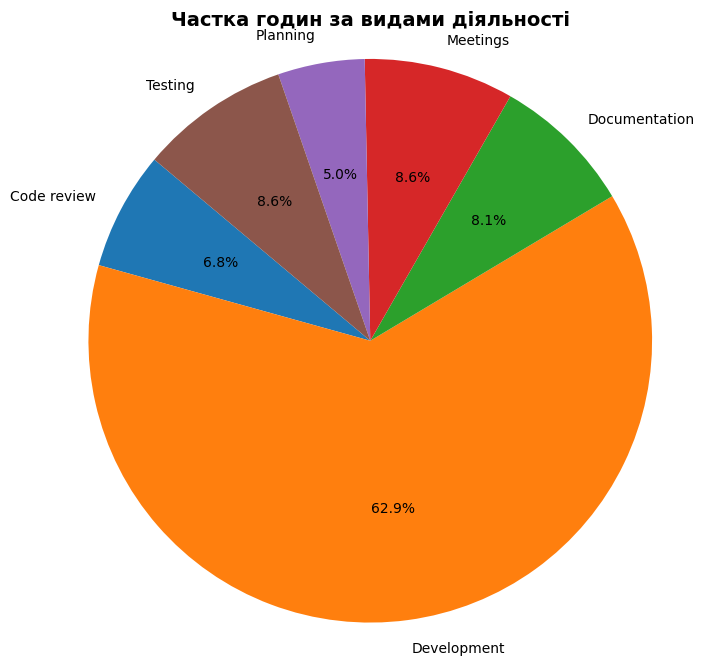

In [10]:
import matplotlib.pyplot as plt

# Групуємо дані за видом діяльності та сумуємо години
activity_hours = df.groupby('activity')['hours'].sum()

# Створюємо графік
plt.figure(figsize=(8, 8))
plt.pie(
    activity_hours,
    labels=activity_hours.index,
    autopct='%1.1f%%',
    startangle=140
)

# Додаємо заголовок та вирівнюємо пропорції
plt.title('Частка годин за видами діяльності', fontsize=14, fontweight='bold')
plt.axis('equal')  # Робить діаграму ідеально круглою

plt.show()

In [12]:
df["activity"]

,activity
0,Development
1,Code review
2,Development
3,Meetings
4,Development
5,Meetings
6,Documentation
7,Code review
8,Testing
9,Planning


In [13]:
df.columns

Index(['member', 'activity', 'hours', 'week', 'project'], dtype='object')